# Supplementary Figure S16 — H₂O and CO₂ correlations

Standalone, function-free workflow for the eight-panel volatile-correlation figure. The original four H₂O comparisons are retained, and four directly matched total-CO₂ comparisons are added below them.

## Shared setup for Figure S16

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.markers import MarkerStyle
from matplotlib.path import Path as MarkerPath
from IPython.display import display

DECHERT_DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
USER_DATA_DIRECTORY = Path('/replace/with/your/folder/containing/the/three/supplemental/files')
DATA_DIRECTORY = DECHERT_DATA_DIRECTORY
# DATA_DIRECTORY = USER_DATA_DIRECTORY

PROJECT_ROOT = None
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if candidate.name == 'Nov6_AllFigures':
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start in Nov6_AllFigures or one of its figure folders.')

FIGURE_DIRECTORY = PROJECT_ROOT / 'Figure_S16_H2O_vs_4'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S16_H2O_vs_4_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

WORKBOOK_PATHS = {
    'S1': DATA_DIRECTORY / 'Dechert_S1_AllData.xlsx',
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement}: required supplemental file not found: {path}')

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
FIGURE_WIDTH_IN = DOUBLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 5.8
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300

PUBLICATION_FONT = 'Arial'
if PUBLICATION_FONT not in {entry.name for entry in font_manager.fontManager.ttflist}:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)

mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT, 'axes.labelsize': BASE_TEXT_SIZE_PT,
    'axes.titlesize': BASE_TEXT_SIZE_PT, 'xtick.labelsize': BASE_TEXT_SIZE_PT,
    'ytick.labelsize': BASE_TEXT_SIZE_PT, 'legend.fontsize': BASE_TEXT_SIZE_PT,
    'legend.title_fontsize': BASE_TEXT_SIZE_PT,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': True, 'axes.spines.right': True, 'axes.linewidth': 0.5,
    'lines.linewidth': 0.75, 'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'savefig.facecolor': 'white', 'savefig.transparent': False,
    'mathtext.fontset': 'custom', 'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic', 'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

SAMPLE_COLORS = {'74D': '#F4A261', '74A': '#D55E00', '75': '#56B4E9', '76A': '#0072B2'}
SAMPLE_LABELS = {'74D': 'B Middle', '74A': 'B Base', '75': 'G Top', '76A': 'G Middle'}
DATA_TYPE_LABELS = {
    'plag': 'Plagioclase-hosted MI',
    'pxy': 'Pyroxene-hosted MI',
    'matrix_glass': 'Matrix glass',
}

# Approved marker geometry from 00_Setup.
MARKER_SPANS_PT = {'plag': 6.0, 'pxy': 6.0, 'matrix_glass': 6.0}
MARKER_LETTERS = {'plag': 'o', 'pxy': 's', 'matrix_glass': 'x'}
MARKER_PATHS = {}
SCATTER_STYLES = {}

for category, marker in MARKER_LETTERS.items():
    span = MARKER_SPANS_PT[category]
    if marker == 'x':
        relative_arm_width = 0.14
        half_arm = relative_arm_width / 2
        vertices = np.array([
            [-half_arm, -0.5], [half_arm, -0.5],
            [half_arm, -half_arm], [0.5, -half_arm],
            [0.5, half_arm], [half_arm, half_arm],
            [half_arm, 0.5], [-half_arm, 0.5],
            [-half_arm, half_arm], [-0.5, half_arm],
            [-0.5, -half_arm], [-half_arm, -half_arm],
            [-half_arm, -0.5],
        ])
        marker_path = MarkerPath(vertices, closed=True)
        edge_width = 0.0
    else:
        standard_marker = MarkerStyle(marker)
        marker_path = standard_marker.get_path().transformed(standard_marker.get_transform())
        edge_width = MINIMUM_LINE_WIDTH_PT

    bounds = marker_path.get_extents()
    vertices = marker_path.vertices.copy()
    vertices[:, 0] = (vertices[:, 0] - (bounds.x0 + bounds.x1) / 2) / bounds.width
    vertices[:, 1] = (vertices[:, 1] - (bounds.y0 + bounds.y1) / 2) / bounds.height
    normalized_path = MarkerPath(vertices, marker_path.codes)

    MARKER_PATHS[category] = normalized_path
    SCATTER_STYLES[category] = {
        'marker': normalized_path,
        's': (span - edge_width) ** 2,
        'linewidths': edge_width,
        'edgecolors': 'none' if marker == 'x' else 'black',
    }

print('Figure directory:', FIGURE_DIRECTORY)
print('Publication font:', PUBLICATION_FONT_PATH)
print('Figure dimensions:', FIGURE_WIDTH_IN, 'x', FIGURE_HEIGHT_IN, 'in')

Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S16_H2O_vs_4
Publication font: /System/Library/Fonts/Supplemental/Arial.ttf
Figure dimensions: 7.25 x 5.8 in


## Figure S16-specific data preparation

The shared setup ends above. This figure reads only Supplement 1, sheet `MI_Hosts_Plag_Pxy`. Rows flagged `Discard_SIMS == yes` are excluded. Alkalis use the existing anhydrous-normalized SEM fields and only rows marked eligible for SEM-glass plotting. The upper row uses final H₂O; the lower row uses final total CO₂. Missing values remain missing, and every panel uses its own finite-value subset.

In [2]:
source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Hosts_Plag_Pxy')

H2O_COLUMN = 'H2O matrix wt% USE_SIMS'
CO2_COLUMN = 'Total_CO2_ppm_final'
X_COLUMNS = [
    'Na2O_SEMGlass_AnhydoNorm',
    'K2O_SEMGlass_AnhydoNorm',
    'F_mtx ppm_SIMS',
    'Cl_mtx ppm_SIMS',
]
X_LABELS = ['Na$_2$O (wt%)', 'K$_2$O (wt%)', 'F (ppm)', 'Cl (ppm)']
SHORT_X_NAMES = ['Na$_2$O', 'K$_2$O', 'F', 'Cl']

data = source.copy()
data['sample_key'] = np.select(
    [
        data['base_name'].astype('string').str.startswith('74D'),
        data['base_name'].astype('string').str.startswith('74A'),
        data['base_name'].astype('string').str.startswith('75'),
        data['base_name'].astype('string').str.startswith('76A'),
    ],
    ['74D', '74A', '75', '76A'],
    default='unmapped',
)
data['phase_key'] = data['mineral_phase'].astype('string').str.strip().str.casefold().replace({'opx': 'pxy'})
data['data_type'] = np.where(
    data['base_name'].astype('string').str.contains('MTX', case=False, na=False),
    'matrix_glass',
    data['phase_key'],
)
data['discard_sims'] = data['Discard_SIMS'].astype('string').str.strip().str.casefold().eq('yes').fillna(False)

for column in [H2O_COLUMN, CO2_COLUMN, *X_COLUMNS]:
    data[column] = pd.to_numeric(data[column], errors='coerce').replace([np.inf, -np.inf], np.nan)

# Na2O and K2O are plotted only where the workbook marks the SEM glass analysis as eligible.
sem_eligible = data['Plot_Eligible_SEM_Glass'].eq(True)
data.loc[~sem_eligible, X_COLUMNS[0:2]] = np.nan

plot_source = data.loc[
    ~data['discard_sims']
    & data['sample_key'].isin(SAMPLE_COLORS)
    & data['data_type'].isin(['plag', 'pxy', 'matrix_glass'])
].copy()

mi_rows = plot_source.loc[plot_source['data_type'].isin(['plag', 'pxy'])].copy()
matrix_rows = plot_source.loc[plot_source['data_type'].eq('matrix_glass')].copy()

population_summary = pd.DataFrame({
    'population': [
        'Source rows',
        'SIMS-discard rows excluded',
        'Retained MI rows',
        'Retained matrix-glass rows',
    ],
    'count': [
        len(source),
        int(data['discard_sims'].sum()),
        len(mi_rows),
        len(matrix_rows),
    ],
})
display(population_summary)

if population_summary['count'].tolist() != [212, 13, 186, 13]:
    raise ValueError('The retained Figure S16 population has changed; review the filtering before plotting.')

,population,count
0,Source rows,212
1,SIMS-discard rows excluded,13
2,Retained MI rows,186
3,Retained matrix-glass rows,13


## Plot and export Figure S16

,panel,x_variable,y_variable,MI finite pairs,matrix-glass finite pairs
0,A,Na2O_SEMGlass_AnhydoNorm,H2O matrix wt% USE_SIMS,112,3
1,B,K2O_SEMGlass_AnhydoNorm,H2O matrix wt% USE_SIMS,112,3
2,C,F_mtx ppm_SIMS,H2O matrix wt% USE_SIMS,116,3
3,D,Cl_mtx ppm_SIMS,H2O matrix wt% USE_SIMS,116,3
4,E,Na2O_SEMGlass_AnhydoNorm,Total_CO2_ppm_final,112,3
5,F,K2O_SEMGlass_AnhydoNorm,Total_CO2_ppm_final,112,3
6,G,F_mtx ppm_SIMS,Total_CO2_ppm_final,116,3
7,H,Cl_mtx ppm_SIMS,Total_CO2_ppm_final,116,3


findfont: Failed to find font weight normal, now using 0.


Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S16_H2O_vs_4/Figure_S16_H2O_vs_4_Final/Figure_S16_Volatile_Correlations_with_H2O_CO2.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S16_H2O_vs_4/Figure_S16_H2O_vs_4_Final/Figure_S16_Volatile_Correlations_with_H2O_CO2.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S16_H2O_vs_4/Figure_S16_H2O_vs_4_Final/Figure_S16_Volatile_Correlations_with_H2O_CO2.svg


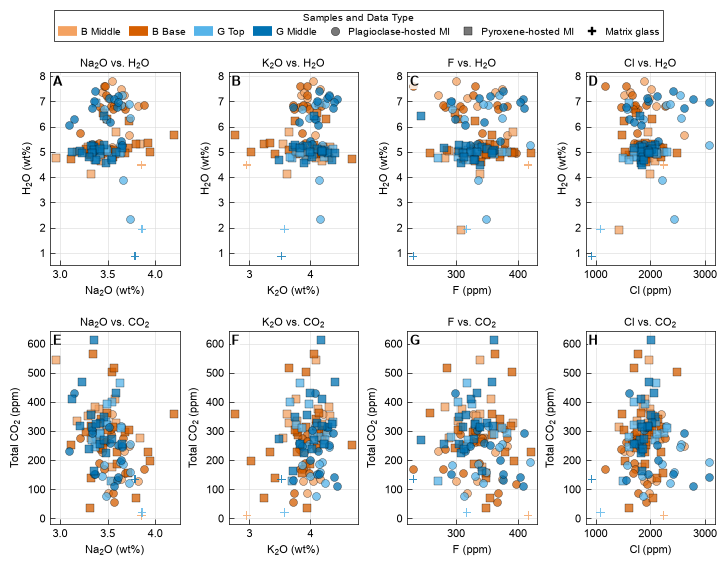

In [3]:
figure, axes = plt.subplots(
    2, 4,
    figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN),
)
axes = np.asarray(axes)
PANEL_LETTERS = list('ABCDEFGH')
Y_COLUMNS = [H2O_COLUMN] * 4 + [CO2_COLUMN] * 4
Y_LABELS = ['H$_2$O (wt%)'] * 4 + ['Total CO$_2$ (ppm)'] * 4
ROW_NAMES = ['H$_2$O'] * 4 + ['CO$_2$'] * 4

panel_counts = []

for panel_index, axis in enumerate(axes.ravel()):
    x_index = panel_index % 4
    x_column = X_COLUMNS[x_index]
    x_label = X_LABELS[x_index]
    y_column = Y_COLUMNS[panel_index]
    y_label = Y_LABELS[panel_index]
    row_name = ROW_NAMES[panel_index]

    for sample_key, color in SAMPLE_COLORS.items():
        matrix_subset = matrix_rows.loc[
            matrix_rows['sample_key'].eq(sample_key)
            & matrix_rows[x_column].notna()
            & matrix_rows[y_column].notna()
        ]
        axis.scatter(
            matrix_subset[x_column],
            matrix_subset[y_column],
            color=color,
            alpha=0.80,
            zorder=3,
            **SCATTER_STYLES['matrix_glass'],
        )

        for phase in ['plag', 'pxy']:
            mi_subset = mi_rows.loc[
                mi_rows['sample_key'].eq(sample_key)
                & mi_rows['data_type'].eq(phase)
                & mi_rows[x_column].notna()
                & mi_rows[y_column].notna()
            ]
            axis.scatter(
                mi_subset[x_column],
                mi_subset[y_column],
                facecolor=color,
                alpha=0.75,
                zorder=3,
                **SCATTER_STYLES[phase],
            )

    panel_counts.append({
        'panel': PANEL_LETTERS[panel_index],
        'x_variable': x_column,
        'y_variable': y_column,
        'MI finite pairs': int((mi_rows[x_column].notna() & mi_rows[y_column].notna()).sum()),
        'matrix-glass finite pairs': int((matrix_rows[x_column].notna() & matrix_rows[y_column].notna()).sum()),
    })

    axis.set_xlabel(x_label)
    axis.set_ylabel(y_label)
    axis.set_title(f'{SHORT_X_NAMES[x_index]} vs. {row_name}', pad=3)
    axis.grid(True, color='#D9D9D9', linewidth=0.4)
    axis.set_axisbelow(True)
    axis.text(
        0.02, 0.98, PANEL_LETTERS[panel_index],
        transform=axis.transAxes,
        ha='left', va='top',
        fontsize=PANEL_LABEL_SIZE_PT,
        fontweight='bold',
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.80, 'pad': 0.3},
        zorder=10,
    )
    for spine in axis.spines.values():
        spine.set_visible(True)

panel_counts = pd.DataFrame(panel_counts)
display(panel_counts)

sample_handles = [
    Line2D(
        [0, 1], [0, 0],
        color=SAMPLE_COLORS[sample_key],
        linewidth=7,
        solid_capstyle='butt',
        label=SAMPLE_LABELS[sample_key],
    )
    for sample_key in ['74D', '74A', '75', '76A']
]
data_type_handles = [
    Line2D(
        [], [],
        linestyle='none',
        marker=MARKER_PATHS[data_type],
        markerfacecolor='#777777' if data_type != 'matrix_glass' else 'black',
        markeredgecolor='black',
        markeredgewidth=MINIMUM_LINE_WIDTH_PT,
        color='black',
        markersize=MARKER_SPANS_PT[data_type],
        label=DATA_TYPE_LABELS[data_type],
    )
    for data_type in ['plag', 'pxy', 'matrix_glass']
]
legend = figure.legend(
    handles=sample_handles + data_type_handles,
    title='Samples and Data Type',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.985),
    ncol=7,
    frameon=True,
    fancybox=False,
    facecolor='white',
    edgecolor='black',
    framealpha=1.0,
    fontsize=7.0,
    title_fontsize=7.0,
    borderpad=0.4,
    handletextpad=0.4,
    columnspacing=0.8,
)
legend.get_frame().set_linewidth(0.5)

figure.subplots_adjust(
    left=0.075, right=0.992,
    bottom=0.09, top=0.87,
    wspace=0.38, hspace=0.34,
)

pdf_path = OUTPUT_DIRECTORY / 'Figure_S16_Volatile_Correlations_with_H2O_CO2.pdf'
png_path = OUTPUT_DIRECTORY / 'Figure_S16_Volatile_Correlations_with_H2O_CO2.png'
svg_path = OUTPUT_DIRECTORY / 'Figure_S16_Volatile_Correlations_with_H2O_CO2.svg'
figure.savefig(pdf_path, format='pdf', facecolor='white', transparent=False)
figure.savefig(png_path, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(svg_path, format='svg', facecolor='white', transparent=False)

print('Saved:', pdf_path)
print('Saved:', png_path)
print('Saved:', svg_path)
plt.show()